# 07 (PH) - Model training: the chosen families on all rows, through the script that goes to SageMaker

**Who worked on this notebook**

| Who | What |
| --- | --- |
| Peter Henskens | Decided the family per horizon after 06 (LightGBM for the day, extra trees for the rest of the month) and that the model is finally built and trained on AWS, which is why 07 trains through the same script that 10 submits; runs the notebook and reviews each result |
| Claude Code (AI assistant) | Drafted `citibike/train/train.py`, `model_inputs()` in `modelling.py`, the notebook, the checks and the dry run of 7 October (appendix). Logged in `genai-log.md` |

**Goal.** 06 named the family per horizon on a 10 % station sample. This notebook trains each family **once on all
training rows** (2,48 M station-days of 2021 - 2024), scores it on the validation year next to the rules and the ridge
floor of 05, and saves the models that 08 tunes and 09 scores on the test period. Because the model is finally built
and trained on AWS (10), the training does not live in notebook cells: it is a script, `citibike/train/train.py`,
that this notebook runs on the laptop and that 10 hands to a SageMaker training job unchanged. 07 is therefore also
the proof that the script works end to end before it costs cloud minutes.

**Products**

| Product | What it is |
| --- | --- |
| `citibike/train/train.py` + `requirements.txt` | the training script and its packages: what 10 sends to SageMaker as `source_dir` |
| `modelling.model_inputs()` | the model-ready table per horizon: the contract between the feature table and the script |
| `data/citibike/model_inputs/<horizon>/{train,valid,test}.parquet` | that table on disk, git-ignored; what 10 copies to S3 |
| `models/citibike/07_<horizon>_<family>/` | `model.joblib` (preprocessing and model in one pipeline), `metrics.json`, `predictions_valid.parquet` |
| the validation tables of parts 3 and 4 | the rules of 05, the ridge floor and the trained family on the same rows, per horizon |

**How it is built**
0. Setup.
1. One script, two runtimes: the design and the data contract.
2. The model inputs per horizon, written to disk, with checks.
3. Horizon day: LightGBM on all rows, the validation table, the number of trees, what the station key adds.
4. Horizon rest of month: extra trees on all rows, the validation table, per length of the horizon.
5. Where the errors are, and what the models lean on.
6. Reading and what carries forward.
Appendix: the dry run of 7 October, the expected runtime, the failures to expect.

**Status: run on all rows on 8 October 2026 (team lead).** The dry run of the appendix ran every cell on a station
sample first; the reading in part 6 is written from the outputs of the full run.

## 0. Setup

Kernel "DataSpell" (Python 3.13), as 05: no PyCaret here, so no separate environment. `lightgbm` is new in
`requirements.txt` (`pip install -r requirements.txt` with that interpreter). No database connection: everything
comes from the Parquet cache of 05 §5 and goes to local folders. The script is imported as a module, so that its
`main()` runs inside this kernel with the same arguments SageMaker passes on the command line.

In [1]:
import json
import sys
import time

import joblib
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

sys.path.insert(0, "..")         # citibike/ -> connection.py and modelling.py
sys.path.insert(0, "../train")   # citibike/train/ -> train.py, the script 10 hands to SageMaker
import train
from connection import fmt, notebook_style
from modelling import (load_features, scorable, score_table, rule_predictions, design, write_model_inputs,
                       FEATURES, MODEL_INPUTS_DIR, MODELS_DIR)

notebook_style()
print(f"python {sys.version.split()[0]}, scikit-learn {sklearn.__version__}, lightgbm {lightgbm.__version__}, pandas {pd.__version__}")

FAMILY = {"day": "lightgbm", "rest_of_month": "extra_trees"}        # the decision of 7 October after 06 (genai-log.md)
RUNS = {horizon: MODELS_DIR / f"07_{horizon}_{family}" for horizon, family in FAMILY.items()}

python 3.13.7, scikit-learn 1.9.1, lightgbm 4.7.0, pandas 2.3.3


## 1. One script, two runtimes

**Decision: the training is a script, not a set of cells.** The model is finally built and trained on AWS, so there
were three ways to get there: (A) train in cells here and write the training again for SageMaker in 10 (two codes
that can drift apart; whichever one 09 compares, the other is unproven); (B) SageMaker's built-in algorithms
(XGBoost is one, as 03 §8 assumed while the family was still open; LightGBM exists there only as a JumpStart model
and extra trees not at all, so the cloud would train another family than the one 06 chose); (C) **script mode**:
one `train.py`, run here as a Python call and in 10 as the entry point of a SageMaker training job in the
scikit-learn framework container, which installs the script's own `requirements.txt`. C is the design: the code
that 09 compares and the API serves is the same whichever machine trained it, and the only AWS-specific lines are
in 10 (the copy of the inputs to S3, the estimator, the job). What SageMaker fixes, the script follows:

| The script needs | Here | On SageMaker (10) |
| --- | --- | --- |
| the inputs | `data/citibike/model_inputs/<horizon>/train.parquet` and `valid.parquet` | the same files in S3, mounted as the channels `train` and `valid` (`SM_CHANNEL_TRAIN`, `SM_CHANNEL_VALID`) |
| the hyperparameters | the arguments of `train.main([...])` | the job's hyperparameters, passed as the same `--name value` arguments |
| where the model goes | `models/citibike/07_<horizon>_<family>/` | `SM_MODEL_DIR`, packed as `model.tar.gz` in S3 |
| where metrics and predictions go | the same folder | `SM_OUTPUT_DATA_DIR`, packed as `output.tar.gz`; the metrics also as `validation:MAE=...` lines in the job log, which the job records |
| the packages | this kernel, from `requirements.txt` | `citibike/train/requirements.txt`, installed by the container before the script starts |

**What the script does**, per run: reads the two files (every column outside `station_key`, `day`, `y`, `scale`,
`actual` is an input); encodes the **station key** as the station's mean target on the training rows, cross-fitted
so that no row sees its own target (what PyCaret did in 06; a target-encoded key is one column where 2.455 dummies
would be a wide, slow matrix); leaves the weekday and the month as numbers (a tree splits a number into ranges, so
"month ≤ 3" is one split where one-hot needs three); fits the family; predicts the validation rows, times `scale`
(1 for the day, the days left for the rest of the month), clipped at 0; scores MAE, RMSE, WAPE and bias with the
same definition as `modelling.metrics()`; for LightGBM also the validation MAE after every 100 trees; saves the
pipeline, the metrics and the predictions. `--sample-stations` keeps a share of the stations for a smoke test (the
dry run of the appendix, and the first cheap job in 10). The arguments, as the script prints them:

In [2]:
print(train.build_parser().format_help())

usage: train.py [-h] --family {lightgbm,extra_trees} [--horizon HORIZON]
                [--train TRAIN] [--valid VALID] [--model-dir MODEL_DIR]
                [--output-dir OUTPUT_DIR] [--station-key {0,1}]
                [--sample-stations SAMPLE_STATIONS] [--seed SEED]
                [--n-jobs N_JOBS] [--n-estimators N_ESTIMATORS]
                [--objective OBJECTIVE] [--learning-rate LEARNING_RATE]
                [--num-leaves NUM_LEAVES]
                [--min-child-samples MIN_CHILD_SAMPLES]
                [--subsample SUBSAMPLE] [--colsample-bytree COLSAMPLE_BYTREE]
                [--curve-every CURVE_EVERY]
                [--min-samples-leaf MIN_SAMPLES_LEAF]
                [--max-features MAX_FEATURES]

Train one family for one horizon on the model inputs of 07 §2.

options:
  -h, --help            show this help message and exit
  --family {lightgbm,extra_trees}
  --horizon HORIZON     day or rest_of_month; recorded in metrics.json,
                        nothing e

## 2. The model inputs per horizon

`modelling.model_inputs()` turns the feature table into what the script reads: the scorable rows of a horizon
(28 days of history and an observed target, as in 05), `design()` of 05 §7 for the inputs, and five columns in
front: `split`, `station_key` as text, `day`, `y` (the target on the model scale), `scale` and `actual`. The
rest-of-month target is the **rate per remaining day**, as in 05 and 06, and `scale` is the days left; for the day
horizon `y` is the departures and `scale` is 1. One Parquet file per split and horizon; the **test file is written
for 09 and 10 and read by no cell of this notebook**. The checks: the rows per split equal the scorable rows of
05 §5, no input is empty, and the first rows show the layout.

In [3]:
df = load_features()
overview = pd.concat({horizon: write_model_inputs(df, horizon) for horizon in FAMILY}, names=["horizon", "split"])
display(overview)

for horizon in FAMILY:
    for split in ["train", "valid", "test"]:
        expected = int(((df.split == split) & scorable(df, horizon)).sum())
        assert overview.loc[(horizon, split), "rows"] == expected, f"{horizon} {split}: {expected} scorable rows expected"
inputs = pd.read_parquet(MODEL_INPUTS_DIR / "day" / "train.parquet")
assert not inputs.isna().any().any(), "an input is empty"
print(f"day inputs: {', '.join(c for c in inputs.columns if c not in train.META)}")
print(f"rest-of-month inputs: {', '.join(FEATURES['rest_of_month'])}")
inputs.head(3)

3.872.821 rows from data\citibike\station_day_features.parquet


rows  stations  columns    MB
horizon       split                                    
day           train  2480425.0    2229.0     27.0  75.8
              valid   779151.0    2225.0     27.0  22.7
              test    537818.0    2328.0     27.0  15.0
rest_of_month train  2476569.0    2229.0     26.0  97.9
              valid   778126.0    2224.0     26.0  31.9
              test    536450.0    2325.0     26.0  21.5

day inputs: dep_lag_1, dep_lag_7, dep_lag_14, dep_lag_28, dep_mean_7, dep_mean_4_weeks, arr_lag_1, arr_mean_7, member_share_28, ebike_share_28, history_days, holiday, day_off, holiday_lag_7, tmax_c, tmin_c, prcp_mm, snow_mm, snow_depth_mm, wind_ms, iso_dow, month
rest-of-month inputs: dep_lag_1, dep_lag_7, dep_lag_14, dep_lag_28, dep_mean_7, dep_mean_4_weeks, arr_lag_1, arr_mean_7, member_share_28, ebike_share_28, history_days, holiday, day_off, holiday_lag_7, days_in_horizon, day_of_month, mtd_rate, last_year_rate, has_last_year, iso_dow, month


,station_key,day,y,scale,actual,dep_lag_1,dep_lag_7,dep_lag_14,dep_lag_28,dep_mean_7,dep_mean_4_weeks,arr_lag_1,arr_mean_7,member_share_28,ebike_share_28,history_days,holiday,day_off,holiday_lag_7,tmax_c,tmin_c,prcp_mm,snow_mm,snow_depth_mm,wind_ms,iso_dow,month
0,2733.03,2021-04-24 00:00:00,7,1,7,5,9,6,1,"6,2857","6,25",5,"6,7143","0,51538","0,44615",28,0,0,0,"22,2","11,1",0,0,0,"1,8",6,4
1,2733.03,2021-04-25 00:00:00,6,1,6,7,5,0,2,"6,0000","2,75",14,"7,8571","0,52941","0,44118",29,0,0,0,"17,2","9,4",15,0,0,"2,4",7,4
2,2733.03,2021-04-26 00:00:00,7,1,7,6,8,3,3,"6,1429","4,00",6,"7,4286","0,52143","0,45000",30,0,0,0,"15,6","5,0",0,0,0,"3,9",1,4


## 3. Horizon day

### 3.1 LightGBM on all rows

The hyperparameters are **not tuned** (08's job) but set for 2,5 M rows rather than left at LightGBM's defaults
(100 trees at learning rate 0,1): 1.000 trees at 0,05 take smaller steps and more of them, which a count with a
weekly rhythm, a season and weather needs (3.3 shows whether 1.000 is enough); 63 leaves per tree instead of 31
because the rows afford deeper trees; a leaf holds at least 100 station-days, the floor 06 gave the forests; each
tree sees 80 % of the rows and 80 % of the inputs, which lowers the variance between trees and the fit time. The
objective is the squared error, as in 06 where the families were compared with their defaults; a count objective
(Poisson) or the absolute error (the metric itself) are leads for 08. The dictionary below is the command line of
the run and, in 10, the `hyperparameters` of the SageMaker estimator.

In [4]:
HYPERPARAMETERS = {
    "day": {"n-estimators": 1000, "learning-rate": 0.05, "num-leaves": 63, "min-child-samples": 100,
            "subsample": 0.8, "colsample-bytree": 0.8, "objective": "regression"},
    "rest_of_month": {"n-estimators": 200, "min-samples-leaf": 100, "max-features": 1.0},
}


def argv(horizon: str, **override) -> list[str]:
    """The command line of one run: the family and hyperparameters of the horizon, the files, the model folder."""
    params = {"family": FAMILY[horizon], "horizon": horizon, **HYPERPARAMETERS[horizon],
              "train": MODEL_INPUTS_DIR / horizon / "train.parquet", "valid": MODEL_INPUTS_DIR / horizon / "valid.parquet",
              "model-dir": RUNS[horizon], **override}
    return [token for key, value in params.items() for token in (f"--{key}", str(value))]


def summary(result: dict) -> pd.Series:
    """One column per run: what was fitted, how long, and the error on the fitted rows next to the validation rows."""
    return pd.Series({"family": result["family"], "training rows": result["rows"]["train"], "inputs": len(result["inputs"]),
                      "trees": result["hyperparameters"]["n_estimators"], "fit (s)": result["fit_seconds"],
                      "train MAE": round(result["train"]["MAE"], 2), "validation MAE": round(result["validation"]["MAE"], 2),
                      "validation WAPE %": round(result["validation"]["WAPE_%"], 2),
                      "validation bias": round(result["validation"]["bias"], 2)})


def predictions_of(run_dir, rows: pd.DataFrame) -> pd.Series:
    """The validation predictions a run saved, on the index of rows (validation rows of the feature table)."""
    saved = pd.read_parquet(run_dir / "predictions_valid.parquet")
    keyed = pd.Series(saved.prediction.to_numpy(),
                      index=pd.MultiIndex.from_arrays([saved.station_key.astype(str), saved.day.astype("datetime64[ns]")]))
    wanted = pd.MultiIndex.from_arrays([rows.station_key.astype(str), rows.day.astype("datetime64[ns]")])
    aligned = keyed.reindex(wanted)
    assert not aligned.isna().any(), "a validation row without a prediction: the inputs of part 2 and the run differ"
    return pd.Series(aligned.to_numpy(), index=rows.index)


def ridge_of(horizon: str, rows: pd.DataFrame) -> pd.Series | None:
    """The ridge floor of 05 on the same rows (its saved pipeline), or None when 05 §7.1 has not been run here."""
    path = MODELS_DIR / f"05_ridge_{horizon}.joblib"
    if not path.exists():
        print(f"no {path.name}: run 05 §7.1 to get the ridge floor into the tables")
        return None
    scale = 1 if horizon == "day" else rows.days_in_horizon.to_numpy()
    return pd.Series(joblib.load(path).predict(design(rows)[FEATURES[horizon]]) * scale, index=rows.index).clip(lower=0)

In [5]:
result_day = train.main(argv("day"))
summary(result_day).to_frame("day")

lightgbm day: 2,480,425 training rows, 779,151 validation rows, 23 inputs, 1000 trees, read in 1 s
fitted in 48 s
train:MAE=7.9630 train:RMSE=14.7292 train:WAPE_%=14.6943 train:bias=0.0086
validation:MAE=10.0171 validation:RMSE=19.1159 validation:WAPE_%=17.1013 validation:bias=1.3755
saved model.joblib in C:\localdata\repo\cloud-ai-avenue-5\models\citibike\07_day_lightgbm, metrics.json and predictions_valid.parquet in C:\localdata\repo\cloud-ai-avenue-5\models\citibike\07_day_lightgbm; 127 s in total


,day
family,lightgbm
training rows,2480425
inputs,23
trees,1000
fit (s),47.900000
train MAE,7.960000
validation MAE,10.020000
validation WAPE %,17.100000
validation bias,1.380000


### 3.2 The validation table

The rules of 05 §6, the ridge floor of 05 §7 (its saved pipeline, on the same rows) and the LightGBM of 3.1, all on
**all** scorable validation rows of 2025 with `score_table()`. For scale, 06's numbers on the 10 % sample: 4-week
mean 15,82, LightGBM 11,35; the gain over the best rule is the number to compare, not the MAE. The script's own
validation MAE must equal the table's: one check that the saved predictions are the ones it scored.

In [6]:
valid_day = df[(df.split == "valid") & scorable(df, "day")]
pred_day = predictions_of(RUNS["day"], valid_day)
ridge_day = ridge_of("day", valid_day)
candidates_day = {**rule_predictions(valid_day, "day"), **({"ridge (05)": ridge_day} if ridge_day is not None else {}),
                  "lightgbm (07, all rows)": pred_day}
table_day = score_table(valid_day, candidates_day, "y_day")
assert abs(table_day.loc["lightgbm (07, all rows)", "MAE"] - result_day["validation"]["MAE"]) < 1e-6, "the script scored other rows"
print(f"Validation 2025, horizon day, {fmt(len(valid_day))} station-days")
table_day.round(2)

Validation 2025, horizon day, 779.151 station-days


,MAE,RMSE,WAPE_%,bias,n
method,,,,,
naive (yesterday),"14,87","29,54","25,38","0,04",779.151
seasonal naive (same weekday last week),"16,08","32,34","27,46","0,16",779.151
"mean of the same weekday, 4 weeks","14,57","29,14","24,87","0,17",779.151
ridge (05),"11,92","22,67","20,34","-0,34",779.151
"lightgbm (07, all rows)","10,02","19,12","17,10","1,38",779.151


### 3.3 The number of trees

The validation MAE after every 100 trees, from the metrics of the run (the same model, predicting with its first
*k* trees). A curve still falling at 1.000 says 08 should raise the number of trees or the learning rate; a curve
rising at the end says the last trees fit noise. It is read, not acted on: this notebook trains once.

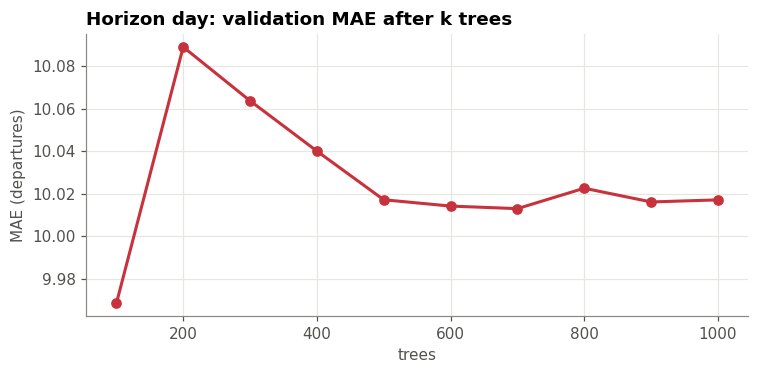

MAE after 100 trees 9,97, after 1000 trees 10,02; lowest 9,97 at 100 trees


In [7]:
curve = pd.Series({int(k): v for k, v in result_day["curve"].items()})
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(curve.index, curve.to_numpy(), marker="o", color="#c8323c")
ax.set_title("Horizon day: validation MAE after k trees")
ax.set_xlabel("trees")
ax.set_ylabel("MAE (departures)")
plt.tight_layout()
plt.show()
print(f"MAE after {curve.index[0]} trees {fmt(curve.iloc[0], '.2f')}, after {curve.index[-1]} trees {fmt(curve.iloc[-1], '.2f')}; "
      f"lowest {fmt(curve.min(), '.2f')} at {curve.idxmin()} trees")

### 3.4 What the station key adds

05 kept the station out of the linear model (decision 3: the lags carry its level) and left it to the tree models
to show what the key adds. One extra run with the same settings and `--station-key 0`: the difference in validation
MAE is what knowing *which* station it is adds over knowing how busy it has been. Not a candidate: the model with
the key is the one in its run folder; this one goes to a folder of its own.

In [8]:
result_day_no_key = train.main(argv("day", **{"station-key": 0, "model-dir": MODELS_DIR / "07_day_lightgbm_no_station_key"}))
pd.concat({"with the station key": summary(result_day), "without": summary(result_day_no_key)}, axis=1)

lightgbm day: 2,480,425 training rows, 779,151 validation rows, 22 inputs, 1000 trees, read in 2 s
fitted in 40 s
train:MAE=8.0219 train:RMSE=14.8336 train:WAPE_%=14.8029 train:bias=0.0057
validation:MAE=10.2376 validation:RMSE=19.4193 validation:WAPE_%=17.4777 validation:bias=1.7689
saved model.joblib in C:\localdata\repo\cloud-ai-avenue-5\models\citibike\07_day_lightgbm_no_station_key, metrics.json and predictions_valid.parquet in C:\localdata\repo\cloud-ai-avenue-5\models\citibike\07_day_lightgbm_no_station_key; 113 s in total


,with the station key,without
family,lightgbm,lightgbm
training rows,2480425,2480425
inputs,23,22
trees,1000,1000
fit (s),47.900000,40.100000
train MAE,7.960000,8.020000
validation MAE,10.020000,10.240000
validation WAPE %,17.100000,17.480000
validation bias,1.380000,1.770000


## 4. Horizon rest of month

### 4.1 Extra trees on all rows

06's winner for this horizon, with the leaf floor it had there (100 station-days) and twice its trees (200 instead
of 100: more trees only lower the variance of the average, at a linear cost in time and memory). Every split
considers every input (`max-features` 1,0, scikit-learn's regression default): extra trees get their randomness
from the thresholds, which are drawn rather than searched, which is also why a tree fits in seconds where a random
forest takes minutes (06: 6,8 s against 12,9 s per fit on the sample). Target and inputs as in 05 §7 and 06 §4:
the rate per remaining day, no weather, the pace and year-earlier rates instead.

In [9]:
result_rest = train.main(argv("rest_of_month"))
summary(result_rest).to_frame("rest of month")

extra_trees rest_of_month: 2,476,569 training rows, 778,126 validation rows, 22 inputs, 200 trees, read in 1 s
fitted in 363 s
train:MAE=87.3721 train:RMSE=209.8313 train:WAPE_%=10.3173 train:bias=-1.6768
validation:MAE=109.8966 validation:RMSE=254.5649 validation:WAPE_%=11.9989 validation:bias=-7.9331
saved model.joblib in C:\localdata\repo\cloud-ai-avenue-5\models\citibike\07_rest_of_month_extra_trees, metrics.json and predictions_valid.parquet in C:\localdata\repo\cloud-ai-avenue-5\models\citibike\07_rest_of_month_extra_trees; 381 s in total


,rest of month
family,extra_trees
training rows,2476569
inputs,22
trees,200
fit (s),363.200000
train MAE,87.370000
validation MAE,109.900000
validation WAPE %,12.000000
validation bias,-7.930000


### 4.2 The validation table, and per length of the horizon

The rules of 05 §6, the ridge floor and the extra trees, on all scorable validation rows, scored on the real total
(rate x days left). 06's sample numbers for scale: weekly pace 160,7, extra trees 118,9. Then the same per days
left in the month, as 05 §7 did: the linear rate over-predicted whole months (257 against 248 for the pace beyond
21 days), which is where a tree model has to prove itself.

In [10]:
valid_rest = df[(df.split == "valid") & scorable(df, "rest_of_month")]
pred_rest = predictions_of(RUNS["rest_of_month"], valid_rest)
ridge_rest = ridge_of("rest_of_month", valid_rest)
candidates_rest = {**rule_predictions(valid_rest, "rest_of_month"), **({"ridge (05)": ridge_rest} if ridge_rest is not None else {}),
                   "extra trees (07, all rows)": pred_rest}
table_rest = score_table(valid_rest, candidates_rest, "y_rest_of_month")
assert abs(table_rest.loc["extra trees (07, all rows)", "MAE"] - result_rest["validation"]["MAE"]) < 1e-6, "the script scored other rows"
print(f"Validation 2025, horizon rest of month, {fmt(len(valid_rest))} station-days")
display(table_rest.round(2))

by_length = valid_rest.assign(**{"days left": pd.cut(valid_rest.days_in_horizon, [0, 7, 14, 21, 31],
                                                      labels=["1 - 7", "8 - 14", "15 - 21", "22 - 31"])})
shown = ("pace, last 7 days x days left", "ridge (05)", "extra trees (07, all rows)")
print("The same, per days left in the month")
score_table(by_length, {k: v for k, v in candidates_rest.items() if k in shown}, "y_rest_of_month", by="days left").round(2)

Validation 2025, horizon rest of month, 778.126 station-days


,MAE,RMSE,WAPE_%,bias,n
method,,,,,
"pace, month to date x days left","169,92","398,23","18,55","21,25",778.126
"pace, last 7 days x days left","149,06","343,09","16,28","13,40",778.126
"last year, same period x growth","147,61","1.504,86","16,12","36,48",778.126
ridge (05),"150,20","314,26","16,40","1,25",778.126
"extra trees (07, all rows)","109,90","254,56","12,00","-7,93",778.126


The same, per days left in the month


,,MAE,RMSE,WAPE_%,bias,n
days left,method,,,,,
1 - 7,"pace, last 7 days x days left","45,08","97,11","19,40","-2,86",179.452
8 - 14,"pace, last 7 days x days left","103,76","210,39","16,33","6,40",179.233
15 - 21,"pace, last 7 days x days left","165,26","347,56","15,82","8,32",178.979
22 - 31,"pace, last 7 days x days left","248,37","500,96","16,14","34,52",240.462
1 - 7,ridge (05),"44,07","90,49","18,96","-11,30",179.452
8 - 14,ridge (05),"102,38","194,91","16,11","-10,99",179.233
15 - 21,ridge (05),"160,67","309,98","15,38","-11,40",178.979
22 - 31,ridge (05),"257,26","462,22","16,71","29,15",240.462
1 - 7,"extra trees (07, all rows)","38,69","79,90","16,65","-9,80",179.452


## 5. Where the errors are, and what the models lean on

The cuts of 05 §8 on the day horizon, now with three methods: the seasonal naive rule, the ridge floor and the
LightGBM. Holidays and rain were where the ridge gained most over the rule and where it still fell short (wet days
25 % worse than dry ones); the station-size quartiles say whether the gain sits with the busy stations (the MAE)
or the quiet ones (the WAPE). Then the ten inputs each model leans on most: the share of the split gain (LightGBM)
or of the impurity decrease (extra trees), a reading aid, not a feature selection. And the busiest station of 2025
over the same eight weeks as 05 §8.1.

In [11]:
cuts = valid_day.assign(**{
    "day group": np.select([valid_day.holiday, valid_day.holiday_lag_7], ["holiday", "a week after a holiday"], "other day"),
    "rain": np.where(valid_day.prcp_mm > 2, "wet (> 2 mm)", "dry"),
    "station size": pd.qcut(valid_day.dep_mean_4_weeks, 4, labels=["Q1 quiet", "Q2", "Q3", "Q4 busy"], duplicates="drop"),
})
methods = {"seasonal naive": valid_day.dep_lag_7, **({"ridge (05)": ridge_day} if ridge_day is not None else {}),
           "lightgbm (07)": pred_day}
for by in ["day group", "rain", "station size"]:
    print(f"Validation 2025, horizon day, by {by}")
    display(score_table(cuts, methods, "y_day", by=by).round(2))

Validation 2025, horizon day, by day group


,,MAE,RMSE,WAPE_%,bias,n
day group,method,,,,,
a week after a holiday,seasonal naive,"19,80","38,08","36,45","-15,35",25.600
holiday,seasonal naive,"24,17","46,91","61,50","17,62",29.886
other day,seasonal naive,"15,62","31,37","26,24","-0,02",723.665
a week after a holiday,ridge (05),"10,37","19,88","19,10","-3,14",25.600
holiday,ridge (05),"14,29","27,52","36,37","4,91",29.886
other day,ridge (05),"11,87","22,54","19,95","-0,46",723.665
a week after a holiday,lightgbm (07),"9,18","17,43","16,90","1,01",25.600
holiday,lightgbm (07),"11,26","21,62","28,65","3,75",29.886
other day,lightgbm (07),"10,00","19,06","16,79","1,29",723.665


Validation 2025, horizon day, by rain


,,MAE,RMSE,WAPE_%,bias,n
rain,method,,,,,
dry,seasonal naive,"15,00","30,29","24,37","-2,73",610.433
wet (> 2 mm),seasonal naive,"20,00","38,87","41,84","10,60",168.718
dry,ridge (05),"11,29","21,26","18,35","-2,11",610.433
wet (> 2 mm),ridge (05),"14,17","27,16","29,63","6,07",168.718
dry,lightgbm (07),"9,74","18,64","15,83","1,33",610.433
wet (> 2 mm),lightgbm (07),"11,01","20,73","23,04","1,53",168.718


Validation 2025, horizon day, by station size


,,MAE,RMSE,WAPE_%,bias,n
station size,method,,,,,
Q1 quiet,seasonal naive,"3,14","5,75","53,94","-0,56",198.006
Q2,seasonal naive,"6,36","8,62","37,67","-0,20",192.534
Q3,seasonal naive,"14,83","21,02","30,57","-0,79",194.034
Q4 busy,seasonal naive,"40,12","60,34","24,54","2,18",194.577
Q1 quiet,ridge (05),"3,93","5,64","67,44","0,34",198.006
Q2,ridge (05),"5,42","7,12","32,11","-0,14",192.534
Q3,ridge (05),"9,84","14,08","20,29","-0,47",194.034
Q4 busy,ridge (05),"28,53","42,16","17,45","-1,10",194.577
Q1 quiet,lightgbm (07),"2,46","3,51","42,15","0,38",198.006


In [12]:
tops = {name: pd.Series(result["importance"]).head(10).round(3)
        for name, result in [("day: lightgbm (share of gain)", result_day), ("rest of month: extra trees (share of impurity decrease)", result_rest)]}
pd.concat({name: s.rename("share").rename_axis("input").reset_index() for name, s in tops.items()}, axis=1)

day: lightgbm (share of gain)         \
                          input  share   
0                    dep_mean_7  0.434   
1                     dep_lag_1  0.175   
2              dep_mean_4_weeks  0.128   
3                    arr_mean_7  0.096   
4                     arr_lag_1  0.089   
5                       prcp_mm  0.022   
6                        tmax_c  0.011   
7                     dep_lag_7  0.008   
8                   station_key  0.006   
9                    dep_lag_14  0.006   

  rest of month: extra trees (share of impurity decrease)         
                                                    input  share  
0                                         arr_mean_7       0.190  
1                                         dep_mean_7       0.186  
2                                           mtd_rate       0.145  
3                                          dep_lag_1       0.096  
4                                        station_key       0.085  
5                                   dep_mean_4_weeks       0.074  
6                                          arr_lag_1       0.074  
7                                          dep_lag_7       0.061  
8                                         dep_lag_14       0.033  
9                                         dep_lag_28       0.030

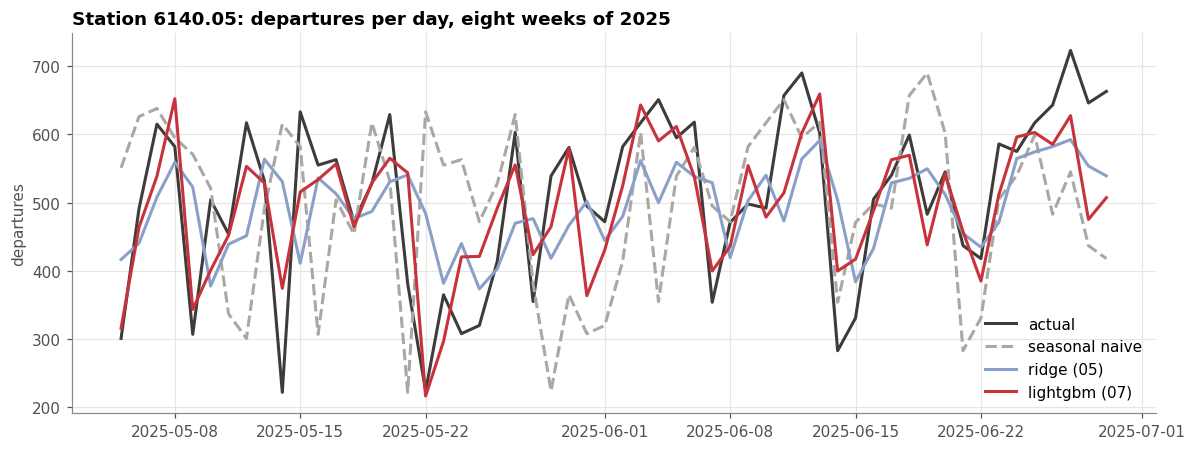

MAE over these 56 days: seasonal naive 127,2, lightgbm 59,0


In [13]:
busiest = valid_day.groupby("station_key").y_day.sum().idxmax()
window = valid_day[(valid_day.station_key == busiest) & (valid_day.day >= "2025-05-05") & (valid_day.day < "2025-06-30")].sort_values("day")

fig, ax = plt.subplots()
ax.plot(window.day, window.y_day, color="#3d3c3a", label="actual")
ax.plot(window.day, window.dep_lag_7, color="#a9a8a4", linestyle="--", label="seasonal naive")
if ridge_day is not None:
    ax.plot(window.day, ridge_day.loc[window.index], color="#8aa0c8", label="ridge (05)")
ax.plot(window.day, pred_day.loc[window.index], color="#c8323c", label="lightgbm (07)")
ax.set_title(f"Station {busiest}: departures per day, eight weeks of 2025")
ax.set_ylabel("departures")
ax.legend()
plt.tight_layout()
plt.show()
print(f"MAE over these {len(window)} days: seasonal naive {fmt((window.dep_lag_7 - window.y_day).abs().mean(), '.1f')}, "
      f"lightgbm {fmt((pred_day.loc[window.index] - window.y_day).abs().mean(), '.1f')}")

## 6. Reading and what carries forward

Run of 8 October 2026 (team lead), kernel DataSpell. Every assertion passed; the model inputs hold exactly the
scorable rows of 05 §5 (2.480.425 / 779.151 / 537.818 for the day, 2.476.569 / 778.126 / 536.450 for the rest of
the month). Validation 2025, MAE in departures per station-day:

| Horizon | Best rule | Ridge (05) | 07 model | Gain over the rule | Fit |
| --- | --- | --- | --- | --- | --- |
| day | 4-week mean **14,57** (WAPE 24,9 %) | 11,92 (20,3 %) | LightGBM **10,02** (17,1 %), bias +1,4 | 31 % (16 % over the ridge) | 48 s, 1.000 trees, 5,8 MB |
| rest of month | weekly pace **149,1** (16,3 %) | 150,2 (16,4 %) | extra trees **109,9** (12,0 %), bias -7,9 | 26 % (27 % over the ridge) | 363 s, 200 trees, **499 MB** |

- **Day: the gain is everywhere.** Holidays 24,2 / 14,3 / 11,3 (seasonal naive / ridge / LightGBM), the week after
  19,8 / 10,4 / 9,2, wet days 20,0 / 14,2 / 11,0: a wet day is now 13 % worse than a dry one, against 25 % for
  the ridge. Every size quartile improves; the quiet quartile, where the ridge was worse than the rule (3,93
  against 3,14), is at 2,46. The bias turned positive (+1,4), mostly in the busy quartile (+3,9).
- **The trees: done after 100.** The validation MAE is lowest after 100 trees (9,97), peaks at 200 (10,09) and is
  flat from 500 on (10,01 - 10,02) while the training MAE keeps falling (7,96). More trees fit noise, not demand.
  08 should search the learning rate, the leaves and the objective, not the number of trees: the squared error aims
  at the mean of a skewed count and the MAE at its median, which is where the +1,4 bias and the flat curve point
  (`regression_l1`, `poisson`).
- **The station key adds 2 %.** 10,02 with it, 10,24 without, consistent with its 0,6 % share of the gain: the lags
  carry the station's level, as 05 decided; the key adds a little at no cost. 05's open question is closed.
- **Rest of month: a large gain with a large model.** Extra trees beat the pace in every length bucket, most
  beyond 21 days (180 against 248), and lean on last week's arrivals and departures and the month-to-date rate.
  The bias flips from -24 at 8 - 21 days to +15 at 22 - 31. The price: 363 s to fit and a model of 499 MB
  (200 trees down to leaves of 100 rows on 2,5 M rows), which the API and S3 will feel. Lead for 08: fewer or
  shallower trees, or LightGBM for this horizon too (3,5 % worse on 06's sample, 6 MB).
- **What they lean on.** Both models use the smoothed recent level (`dep_mean_7`, `arr_mean_7`) far more than any
  single lag; the weather is the first non-history input for the day (rain 2,2 % of the gain, max temperature
  1,1 %). The busiest station over eight weeks: seasonal naive MAE 127, ridge 88 (05), LightGBM 59.

**What 08 - 10 take from here:** the two run folders (`07_day_lightgbm`, `07_rest_of_month_extra_trees`) for 09's
one look at the test period; the model inputs on disk for 10 (copied to S3 as they are); the hyperparameters of
parts 3 and 4 as the start of 08, with the three leads above; the ablation of 3.4 as the answer on the station key.

## Appendix: the dry run of 7 October, the expected runtime, the failures to expect

**Dry run** (Claude, 7 October, this kernel's environment, before the run on all rows). Every cell of this notebook was executed by `nbclient` in the kernel's environment (Python 3.13.7, scikit-learn 1.9.1, lightgbm 4.7.0) on **75 of the 2.455 stations** (120.383 rows of the real Parquet cache; `load_features()` stubbed to that sample, the model inputs and the models in a temporary folder, the ridge files of 05 copied there): 44 s in total, no error, every assertion passed, both charts drawn. The script ran on the sample with 75.597 training and 25.207 validation rows for the day (23 inputs, 1.000 trees, fit 7,5 s) and 75.396 / 25.179 for the rest of the month (22 inputs, 200 trees, fit 3,0 s); the reloaded `model.joblib` reproduces `predictions_valid.parquet` exactly, and the script's validation MAE equals `score_table()` on the same rows. The command line was also run as SageMaker will run it: no `--train` and `--valid`, the two files in channel **directories** named by `SM_CHANNEL_TRAIN` and `SM_CHANNEL_VALID`, the model in `SM_MODEL_DIR` and the metrics and predictions in `SM_OUTPUT_DATA_DIR`; `model.joblib`, `metrics.json` and `predictions_valid.parquet` landed where SageMaker packs them. **The numbers of that run mean nothing for the reading**: on 75 stations the LightGBM curve was lowest at 200 trees and rose to 1.000, which is what 75.000 rows do with 1.000 trees and says nothing about 2,5 M rows.

**Expected runtime on all rows**: an extrapolation from the sample, not a measurement. The fit times scale with the rows (33 times more), so LightGBM should take a few minutes for 1.000 trees and the extra trees a few minutes for 200 (their trees also grow deeper); the model inputs of part 2 (design() on 3,9 M rows, six Parquet files) and the predictions on 779.000 validation rows add a minute or two. Expect **10 - 20 minutes** for the whole notebook and a few GB of memory during the extra trees; the measured times are in the outputs of parts 3 and 4 after the run. **Measured in the run of 8 October:** LightGBM 48 s to fit (127 s with the curve and the predictions), the run without the station key 40 s (113 s), the extra trees 363 s (381 s); the model folders hold 5,8 MB (LightGBM) and 499 MB (extra trees).

| Symptom | Cause | Fix |
| --- | --- | --- |
| `ModuleNotFoundError: No module named 'lightgbm'` | not installed in the kernel's environment | `pip install -r requirements.txt` with that interpreter |
| `FileNotFoundError: ... model_inputs ...` | part 2 has not been run in this environment | run part 2 (it needs the Parquet cache of 05 §5, or the `.env` login to pull the table) |
| `no 05_ridge_day.joblib` printed, no ridge row in the tables | 05 §7.1 has not been run on this laptop | run 05 part 7, or read the tables without the floor |
| the assertion after a validation table | the predictions file belongs to other inputs than part 2 just wrote | run the training cell of that horizon again |
| `MemoryError` in the extra trees | 200 trees on 2,48 M rows on a 16 GB laptop | lower `n-estimators` to 100 or raise `min-samples-leaf`; 10 has the memory of the instance |
| `OSError: access violation` in a LightGBM fit | lightgbm 4.7 next to scikit-learn 1.4 (06 appendix) | only in `.venv-pycaret`; this kernel (scikit-learn 1.9) runs 4.7.0, checked 7 October |